# 01b. Exploratory Data Analysis: Features

**Owner:** Member B (Random Forest)
**Project:** Predicting district-level dengue outbreaks in Sri Lanka two weeks ahead

This notebook studies the candidate input features: climate, geography, demographics and the derived columns. The target is analysed in `01a_eda_target.ipynb`.

**Questions answered here**

1. How are the climate features distributed, and do they contain genuine outliers or errors?
2. How do climate conditions vary through the year and between districts?
3. At what time lag does climate relate to dengue cases?
4. Which features carry information about the outbreak target?
5. Which features are redundant, collinear or leaky?

Every preprocessing decision in step 7 should trace back to a finding in this notebook or in `01a`.

**Rule against test-set snooping.** All statistics are computed on the training years (2007 to 2020) only.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so the shared `src` modules work from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif

from src import config, viz
from src.data_loader import load_raw, load_dataset

viz.set_style()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
raw = load_raw()
df, thresholds = load_dataset()

train = df[df["split"] == "train"].copy()
train_mask_raw = raw["year"].between(*config.TRAIN_YEARS)

print(f"Training rows: {len(train):,} district-weeks, {train['year'].min()} to {train['year'].max()}")
print(f"Outbreak rate (target): {train['target'].mean() * 100:.1f}%")

Training rows: 18,200 district-weeks, 2007 to 2020
Outbreak rate (target): 8.0%


## 1. Feature inventory

The data dictionary from step 5 (`data/data_dictionary.csv`) records a planned role for every column. This section checks those plans against the data.

In [3]:
dictionary = pd.read_csv(ROOT / "data" / "data_dictionary.csv")
dictionary.groupby("group")["column"].apply(", ".join).to_frame("columns")

,columns
group,
Climate,"rainfall_mm, rainfall_lag2, rainfall_lag4, tem..."
Demographic,"population, population_source, population_density"
Epidemiological,"cases, incidence_rate, cases_lag1, cases_zscore"
Location,"district, province, latitude, longitude, coast..."
Time,"year, week, start.date, end.date, month, seaso..."


## 2. Climate distributions

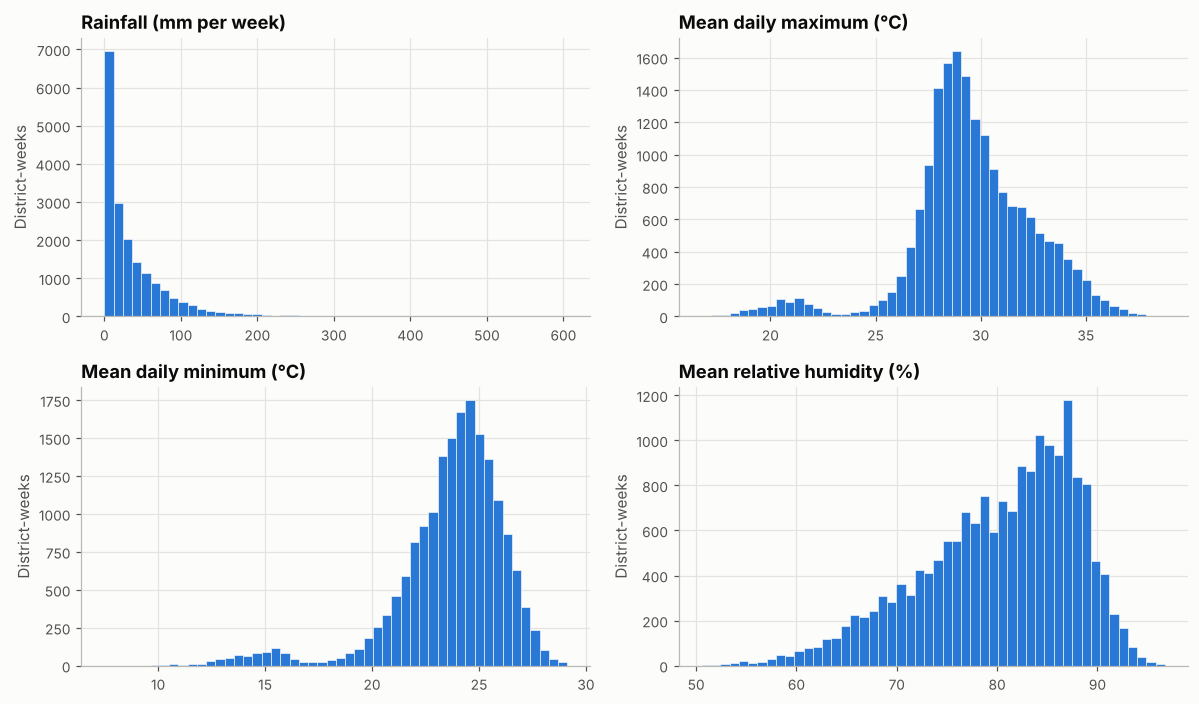

,skewness,min,median,max
rainfall_mm,3.110,0.000,20.300,605.100
temp_max_c,-0.670,16.740,29.370,38.760
temp_min_c,-1.700,7.490,24.090,29.130
humidity_pct,-0.700,50.570,81.710,96.710
log(1 + rainfall),-0.360,NaN,NaN,NaN


In [4]:
climate = ["rainfall_mm", "temp_max_c", "temp_min_c", "humidity_pct"]
labels = {
    "rainfall_mm": "Rainfall (mm per week)",
    "temp_max_c": "Mean daily maximum (°C)",
    "temp_min_c": "Mean daily minimum (°C)",
    "humidity_pct": "Mean relative humidity (%)",
}

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, col in zip(axes.flat, climate):
    ax.hist(train[col], bins=50, color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=0.4)
    ax.set_title(labels[col])
    ax.set_ylabel("District-weeks")
fig.tight_layout()
viz.save(fig, "eda_b_01_climate_distributions")
plt.show()

shape = pd.DataFrame({
    "skewness": train[climate].skew(),
    "min": train[climate].min(),
    "median": train[climate].median(),
    "max": train[climate].max(),
})
shape.loc["log(1 + rainfall)"] = [np.log1p(train["rainfall_mm"]).skew(), np.nan, np.nan, np.nan]
shape.round(2)

**Finding.** Rainfall is strongly right-skewed (skewness about 3.1, with many dry weeks and occasional extreme falls), and log(1 + x) almost removes the skew. The two temperature features are left-skewed, with a separate cluster of cool weeks, and humidity is mildly left-skewed.

**Implication.** Log-transform rainfall and its lags for Logistic Regression. The cool temperature tail needs checking before it is treated as an error (section 4).

## 3. Climate through the year

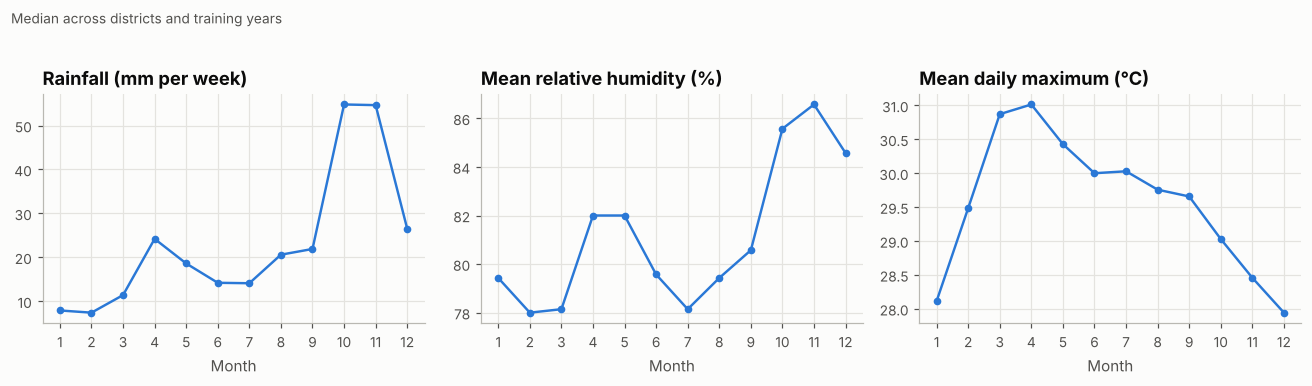

In [5]:
monthly = train.groupby("month")[["rainfall_mm", "humidity_pct", "temp_max_c"]].median()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col in zip(axes, monthly.columns):
    ax.plot(monthly.index, monthly[col], color=viz.BLUE, marker="o", markersize=4)
    ax.set_title(labels[col])
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("Month")
fig.suptitle("Median across districts and training years", x=0.01, ha="left", fontsize=9, color=viz.TEXT_MUTED, y=1.02)
fig.tight_layout()
viz.save(fig, "eda_b_02_climate_seasonality")
plt.show()

**Finding.** Rainfall and humidity follow the monsoon calendar, peaking in April to May and again in October to November, while maximum temperature peaks in March to April and falls through the wetter months. The rainfall peaks arrive about two months before the case peaks seen in `01a` (June to August and December to February), which is what a lagged mosquito-breeding effect would produce.

**Implication.** Climate and season carry overlapping information. A model given both month and climate may split credit between them, which matters when interpreting coefficients or importances.

## 4. Geographic differences

In [6]:
geography = train.groupby("elevation_category").agg(
    districts=(config.DISTRICT_COL, "nunique"),
    temp_min=("temp_min_c", "mean"),
    temp_max=("temp_max_c", "mean"),
    rainfall=("rainfall_mm", "mean"),
    humidity=("humidity_pct", "mean"),
    outbreak_rate=("target", "mean"),
).reindex(["Low", "Mid", "Highland"])
geography["outbreak_rate"] *= 100
geography.round(1)

,districts,temp_min,temp_max,rainfall,humidity,outbreak_rate
elevation_category,,,,,,
Low,17,24.800,30.300,32.600,79.100,8.600
Mid,7,22.100,29.000,45.400,82.100,6.500
Highland,1,14.500,20.700,45.400,85.100,8.400


In [7]:
coolest = train.nsmallest(5, "temp_min_c")[[config.DISTRICT_COL, "year", "week", "temp_min_c", "temp_max_c"]]
print("Coolest district-weeks in the training years:")
coolest

Coolest district-weeks in the training years:


,district,year,week,temp_min_c,temp_max_c
19219,Nuwara Eliya,2017,2,7.486,18.914
19220,Nuwara Eliya,2017,3,8.857,18.971
19271,Nuwara Eliya,2018,2,9.943,17.929
19272,Nuwara Eliya,2018,3,10.029,18.114
19223,Nuwara Eliya,2017,6,10.043,19.700


In [8]:
coastal = train.groupby("coastal_district")["target"].mean().mul(100).rename({0: "inland", 1: "coastal"})
coastal.round(1).to_frame("outbreak rate (%)")

,outbreak rate (%)
coastal_district,
inland,6.900
coastal,8.900


**Finding.** Elevation explains most of the temperature variation: the single Highland district, Nuwara Eliya, averages about 10 °C cooler than the lowlands, and it accounts for the cool tail seen in section 2. These are genuine readings, not errors. Outbreak rates differ only modestly across elevation bands and between coastal and inland districts (roughly 6.5% to 9%), because the threshold is set per district.

**Implication.** Keep the cool-temperature values: removing them would delete a real district. Elevation and coastal status describe districts rather than weeks, so on their own they cannot predict **when** an outbreak happens, only modulate how climate acts in different places.

## 5. At what lag does climate relate to cases?

Mosquitoes need standing water to breed, and the virus needs time to incubate, so rainfall should affect cases only after a delay. Here each climate variable is correlated with the same district's log cases k weeks later, for k = 0 to 16.

Two versions are computed:

* **District-demeaned:** removes stable differences between districts.
* **Seasonal anomaly:** also removes each district's average for that week of the year, so it asks whether an **unusually** wet or hot spell is followed by **unusually** many cases. This guards against a correlation that only reflects both variables sharing the same seasonal cycle.

In [9]:
log_cases = np.log1p(raw[config.CASES_COL])
week_of_year = raw["week"].clip(upper=52)
max_lag = 16

def lagged_correlations(variable):
    """Correlation of log cases now with `variable` k weeks earlier, k = 0..max_lag."""
    demeaned, anomaly = [], []
    for lag in range(max_lag + 1):
        past = raw.groupby(config.DISTRICT_COL)[variable].shift(lag)
        frame = pd.DataFrame({
            "y": log_cases, "x": past,
            "district": raw[config.DISTRICT_COL], "woy": week_of_year,
        })[train_mask_raw].dropna()
        for keys, store in [(["district"], demeaned), (["district", "woy"], anomaly)]:
            y = frame["y"] - frame.groupby(keys)["y"].transform("mean")
            x = frame["x"] - frame.groupby(keys)["x"].transform("mean")
            store.append(np.corrcoef(y, x)[0, 1])
    return pd.DataFrame({"district-demeaned": demeaned, "seasonal anomaly": anomaly})

lag_corr = {var: lagged_correlations(var) for var in climate}

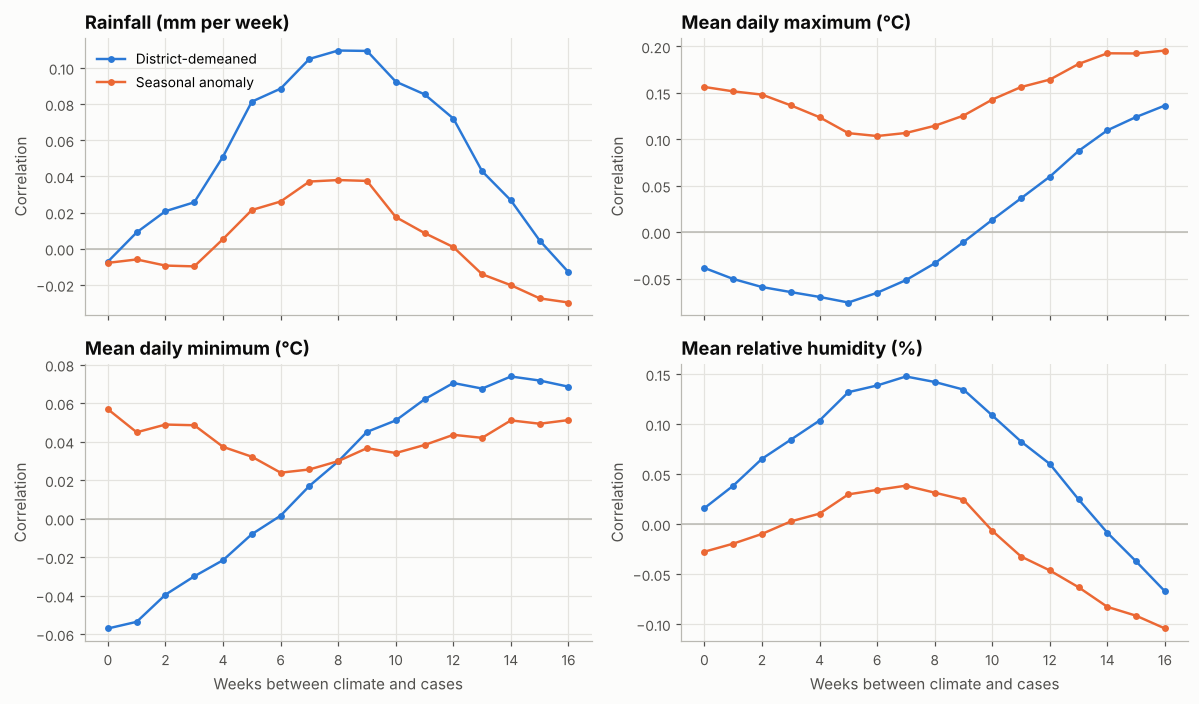

,peak lag (demeaned),r at peak (demeaned),peak lag (anomaly),r at peak (anomaly)
rainfall_mm,8.000,0.110,8.000,0.038
temp_max_c,16.000,0.136,16.000,0.196
temp_min_c,14.000,0.074,0.000,0.057
humidity_pct,7.000,0.148,16.000,-0.104


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for ax, var in zip(axes.flat, climate):
    table = lag_corr[var]
    ax.axhline(0, color=viz.NEUTRAL, linewidth=1)
    ax.plot(table.index, table["district-demeaned"], color=viz.BLUE, marker="o", markersize=3.5, label="District-demeaned")
    ax.plot(table.index, table["seasonal anomaly"], color=viz.ORANGE, marker="o", markersize=3.5, label="Seasonal anomaly")
    ax.set_title(labels[var])
    ax.set_ylabel("Correlation")
for ax in axes[1]:
    ax.set_xlabel("Weeks between climate and cases")
axes[0, 0].legend(loc="upper left")
fig.tight_layout()
viz.save(fig, "eda_b_03_climate_lag_correlation")
plt.show()

peaks = pd.DataFrame({
    var: {
        "peak lag (demeaned)": int(t["district-demeaned"].abs().idxmax()),
        "r at peak (demeaned)": t["district-demeaned"].iloc[t["district-demeaned"].abs().idxmax()],
        "peak lag (anomaly)": int(t["seasonal anomaly"].abs().idxmax()),
        "r at peak (anomaly)": t["seasonal anomaly"].iloc[t["seasonal anomaly"].abs().idxmax()],
    }
    for var, t in lag_corr.items()
}).T
peaks.round(3)

**Finding.** Rainfall and humidity relate to cases most strongly about **7 to 9 weeks** later, which fits the breeding and incubation cycle. The correlations are weak (r about 0.1 to 0.15) and shrink to about 0.04 once the shared seasonal cycle is removed, so much of the raw climate signal is seasonality. The clearest anomaly signal is temperature: warmer-than-usual maximum temperatures are followed by more cases at every lag shown (r about 0.10 to 0.20). Minimum temperature has almost no relationship.

**Implication.**

* The dataset's own lags (`rainfall_lag2`, `rainfall_lag4`) are **shorter than the useful window**. Because the model predicts two weeks ahead, a lag of about 8 weeks relative to the outcome means about **6 weeks before the prediction week**. Step 7 should engineer rainfall and humidity lags or rolling means covering roughly 5 to 8 weeks before the prediction week.
* A temperature anomaly feature (this week's maximum temperature minus the district's usual value for that week, fitted on training years) is worth testing.
* Climate alone will not drive the predictions; recent case history will (section 6). Climate's role is to help anticipate changes that case history cannot see coming.

## 6. Which features carry information about the target?

Two measures are used on the training years:

* **Standardised mean difference (SMD):** how far apart the outbreak and non-outbreak groups are, in pooled standard deviations. Linear and easy to read.
* **Mutual information (MI):** captures any dependence, linear or not (lecture 2, filter methods).

The three leaky columns are excluded here and examined separately in section 8.

In [11]:
candidates = [
    "cases_lag1", "rainfall_mm", "rainfall_lag2", "rainfall_lag4",
    "temp_max_c", "temp_min_c", "humidity_pct",
    "population", "population_density", "area_km2",
    "latitude", "longitude", "coastal_district", "month", "week",
]
positive, negative = train[train["target"] == 1], train[train["target"] == 0]
pooled_sd = np.sqrt((positive[candidates].var() + negative[candidates].var()) / 2)
smd = (positive[candidates].mean() - negative[candidates].mean()) / pooled_sd

X = train[candidates].fillna(train[candidates].median())
discrete = [c in ("coastal_district", "month", "week") for c in candidates]
mi = pd.Series(
    mutual_info_classif(X, train["target"], discrete_features=discrete, random_state=config.RANDOM_SEED),
    index=candidates,
)

relevance = pd.DataFrame({"SMD": smd, "mutual information": mi}).sort_values("mutual information", ascending=False)
relevance.round(3)

,SMD,mutual information
population_density,0.030,0.116
population,0.004,0.111
cases_lag1,0.776,0.070
week,0.179,0.007
month,0.241,0.006
latitude,0.004,0.006
rainfall_lag2,0.161,0.004
rainfall_lag4,0.192,0.003
humidity_pct,0.171,0.003
temp_max_c,-0.086,0.002


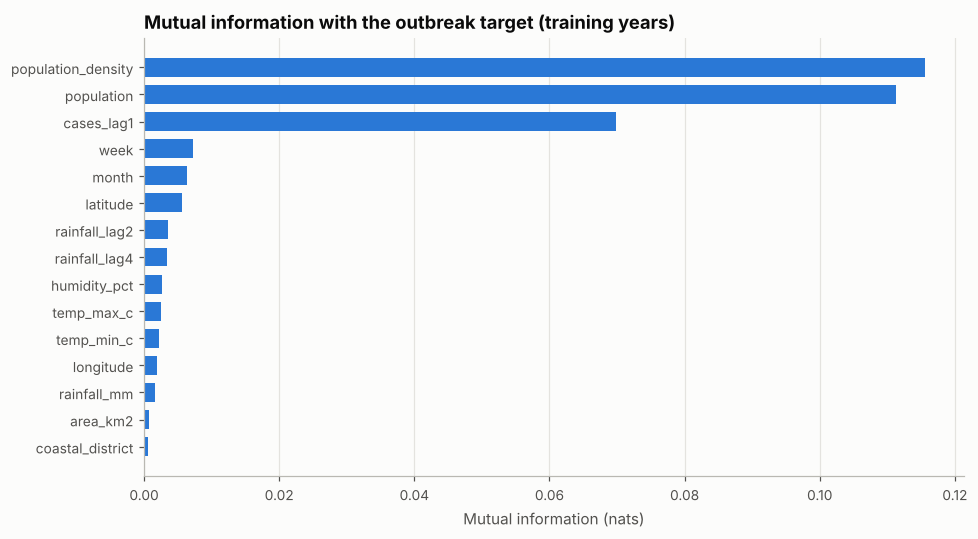

In [12]:
ordered = relevance["mutual information"].sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(ordered.index, ordered.values, color=viz.BLUE, height=0.7)
ax.set_title("Mutual information with the outbreak target (training years)")
ax.set_xlabel("Mutual information (nats)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save(fig, "eda_b_04_mutual_information")
plt.show()

**Finding.** Three features stand far above the rest: `cases_lag1`, `population` and `population_density`. Recent cases are expected to be informative (the outbreak group averages about seven times as many cases the previous week). The two population features are a surprise and are examined next. Every climate feature has small MI on its own.

### 6.1 Why do the population features score so highly?

`population` changes once a year per district, so each value identifies one district in one year. Outbreaks are concentrated in particular years (2017, 2019), so a feature that identifies the year can look predictive without describing anything about transmission.

In [13]:
values_per_district_year = raw.groupby([config.DISTRICT_COL, "year"])["population"].nunique().max()
print(f"Distinct population values within any district-year: {values_per_district_year}")

district_year_id = train.groupby([config.DISTRICT_COL, "year"]).ngroup()
comparison = pd.DataFrame({
    "year": train["year"],
    "district-year identifier": district_year_id,
    "population": train["population"],
    "population_density": train["population_density"],
    "area_km2 (fixed per district)": train["area_km2"],
})
mi_check = pd.Series(
    mutual_info_classif(comparison, train["target"], discrete_features=[True, True, False, False, False],
                        random_state=config.RANDOM_SEED),
    index=comparison.columns,
)
mi_check.round(3).to_frame("mutual information")

Distinct population values within any district-year: 1


,mutual information
year,0.090
district-year identifier,0.122
population,0.113
population_density,0.115
area_km2 (fixed per district),0.001


**Finding.** The population features carry almost exactly as much information as a pure district-year identifier, while `area_km2`, which is fixed per district, carries almost none. Their apparent strength comes from **recognising which year it is**, not from population size.

**Implication.** This is a subtle leakage risk. Random Forest in particular could learn rules such as "this exact population value means 2017" that will not transfer to 2023 to 2025. Options for step 7:

* use a district-level constant instead, such as the log of the district's mean population density over the training years, or
* keep the feature but test its effect on validation performance with and without it.

The decision and its evidence belong in the preprocessing section of the report.

## 7. Collinearity between features

Highly correlated features make Logistic Regression coefficients unstable and hard to interpret. Random Forest is largely unaffected in accuracy, but its feature importances get split between correlated features.

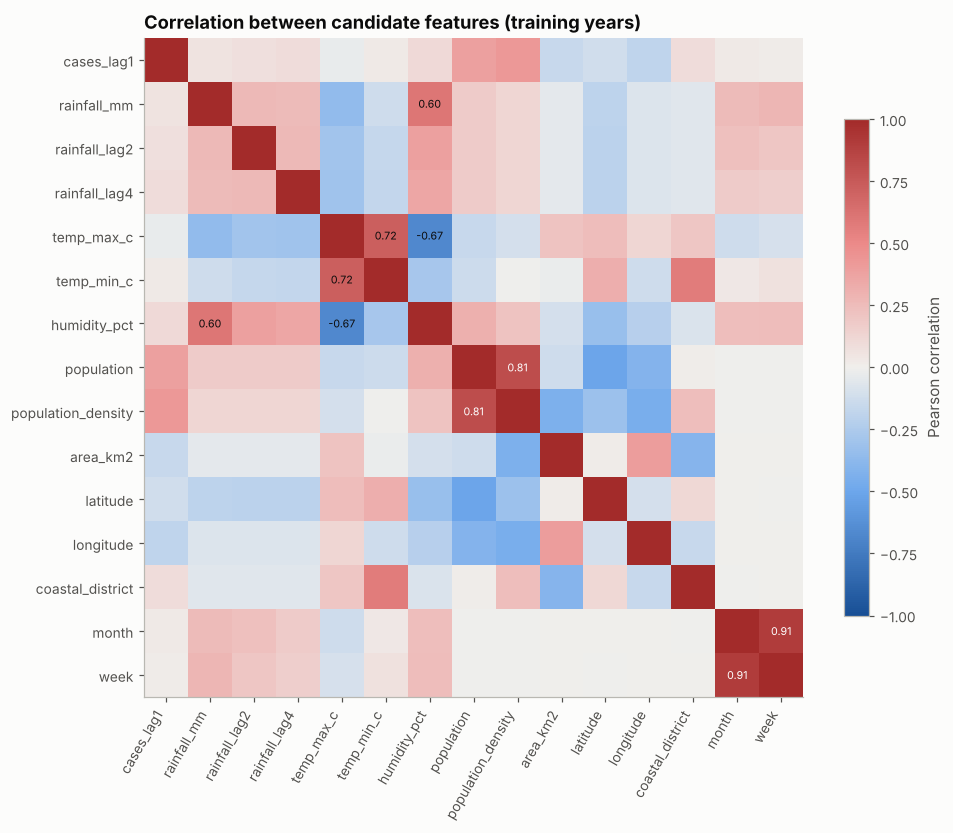

In [14]:
numeric = [c for c in candidates]
corr = train[numeric].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
image = ax.imshow(corr.values, cmap=viz.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric)))
ax.set_yticks(range(len(numeric)))
ax.set_xticklabels(numeric, rotation=60, ha="right")
ax.set_yticklabels(numeric)
ax.grid(False)
for i in range(len(numeric)):
    for j in range(len(numeric)):
        value = corr.iloc[i, j]
        if i != j and abs(value) >= 0.6:
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(value) > 0.75 else viz.TEXT)
fig.colorbar(image, ax=ax, shrink=0.75, label="Pearson correlation")
ax.set_title("Correlation between candidate features (training years)")
fig.tight_layout()
viz.save(fig, "eda_b_05_feature_correlation")
plt.show()

In [15]:
def variance_inflation(frame):
    """VIF for each column: 1 / (1 - R^2) from regressing it on all the others."""
    z = (frame - frame.mean()) / frame.std()
    vif = {}
    for col in z.columns:
        y = z[col].to_numpy()
        others = np.column_stack([np.ones(len(z)), z.drop(columns=col).to_numpy()])
        coef, *_ = np.linalg.lstsq(others, y, rcond=None)
        r2 = 1 - ((y - others @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        vif[col] = 1 / (1 - r2)
    return pd.Series(vif)

vif = variance_inflation(train[numeric].dropna()).sort_values(ascending=False)

pairs = [
    (a, b, corr.loc[a, b])
    for i, a in enumerate(numeric) for b in numeric[i + 1:]
    if abs(corr.loc[a, b]) >= 0.6
]
print("Pairs with |r| >= 0.6:")
for a, b, r in sorted(pairs, key=lambda p: -abs(p[2])):
    print(f"  {a:20s} {b:20s} r = {r:+.2f}")

vif.round(1).to_frame("VIF")

Pairs with |r| >= 0.6:
  month                week                 r = +0.91
  population           population_density   r = +0.81
  temp_max_c           temp_min_c           r = +0.72
  temp_max_c           humidity_pct         r = -0.67
  rainfall_mm          humidity_pct         r = +0.60


,VIF
temp_max_c,6.500
week,6.100
month,6.100
temp_min_c,5.800
population,5.600
population_density,5.000
humidity_pct,3.800
coastal_district,2.400
area_km2,2.100
longitude,1.900


**Finding.** The strongest overlaps are `month` with `week` (they encode the same calendar position), `population` with `population_density`, the two temperatures with each other, and maximum temperature against humidity (hot weeks are drier). VIF values stay below 10, so collinearity is moderate rather than severe, with the calendar and temperature features highest.

**Implication.** Keep one calendar encoding (a cyclical week encoding, as recommended in `01a`) rather than both `week` and `month`. Keep at most one population feature. Use L2 regularisation in Logistic Regression, which stabilises coefficients when features overlap.

## 8. Redundant and leaky columns, confirmed

The data dictionary flagged several columns. This section confirms each flag directly from the data.

In [16]:
per_district = raw.groupby(config.DISTRICT_COL)[["latitude", "longitude", "area_km2", "province",
                                                  "coastal_district", "elevation_category"]].nunique().max()
per_month = raw.groupby("month")[["season", "monsoon_season"]].nunique().max()

redundancy = pd.concat([
    per_district.rename(lambda c: f"{c}: values per district"),
    per_month.rename(lambda c: f"{c}: values per month"),
]).to_frame("max distinct values")
redundancy

,max distinct values
latitude: values per district,1
longitude: values per district,1
area_km2: values per district,1
province: values per district,1
coastal_district: values per district,1
elevation_category: values per district,1
season: values per month,1
monsoon_season: values per month,1


In [17]:
leaky = train[["cases", "incidence_rate", "cases_zscore", "is_epidemic_year", "cases_lag1", "target"]].copy()
# Recompute the z-score with each district's mean and population SD over the FULL 2006 to 2025 series.
full_period = raw.groupby(config.DISTRICT_COL)[config.CASES_COL]
recomputed_z = (raw[config.CASES_COL] - full_period.transform("mean")) / full_period.transform(lambda s: s.std(ddof=0))
incidence_check = (train["cases"] / train["population"] * 1e5 - train["incidence_rate"]).abs().max()

print(f"Largest gap between incidence_rate and cases / population x 100,000: {incidence_check:.2e}")
print(f"Largest gap between cases_zscore and the full-period z-score: {(raw['cases_zscore'] - recomputed_z).abs().max():.2e}")
flagged_years = sorted(int(y) for y in raw.loc[raw["is_epidemic_year"] == 1, "year"].unique())
print("Years flagged by is_epidemic_year:", flagged_years)

leak_cols = ["incidence_rate", "cases_zscore", "is_epidemic_year"]
mi_leak = pd.Series(
    mutual_info_classif(train[leak_cols + ["cases_lag1"]], train["target"],
                        discrete_features=[False, False, True, False], random_state=config.RANDOM_SEED),
    index=leak_cols + ["cases_lag1"],
)
mi_leak.round(3).to_frame("mutual information with target")

Largest gap between incidence_rate and cases / population x 100,000: 1.42e-14
Largest gap between cases_zscore and the full-period z-score: 1.78e-15
Years flagged by is_epidemic_year: [2009, 2017, 2019]


,mutual information with target
incidence_rate,0.132
cases_zscore,0.164
is_epidemic_year,0.057
cases_lag1,0.070


**Finding.**

* `latitude`, `longitude`, `area_km2`, `province`, `coastal_district` and `elevation_category` each take exactly one value per district: they are district attributes, and `province` adds nothing once `district` is known.
* `season` and `monsoon_season` take exactly one value per month: they are recodings of `month`.
* `incidence_rate` is exactly cases per 100,000, and `cases_zscore` is exactly the within-district z-score of the same week's cases, computed with statistics from the full 2006 to 2025 period, including future years. `is_epidemic_year` marks 2009, 2017 and 2019 with hindsight.
* `incidence_rate` and `cases_zscore` score **higher** mutual information with the target than the legitimate `cases_lag1`, and `is_epidemic_year` comes close to it despite being a single flag per year. This is exactly why they are dangerous: a model would rely on them first.

**Implication.** Drop the three leaky columns, `province`, `end.date` and `population_source` in step 7 (these lists are already in `src/config.py`). Treat the district attributes as one block and choose a single representation of location (for example one-hot district, or latitude and longitude, not every option at once).

## 9. Missing values and outliers

In [18]:
lag_cols = ["cases_lag1", "rainfall_lag2", "rainfall_lag4"]
first_weeks = raw.groupby(config.DISTRICT_COL).cumcount()
missing = pd.DataFrame({
    "missing rows": raw[lag_cols].isna().sum(),
    "all in each district's first k weeks": [
        bool(raw.loc[raw[c].isna()].index.isin(raw.index[first_weeks < k]).all())
        for c, k in zip(lag_cols, [1, 2, 4])
    ],
    "missing rows in training years": train[lag_cols].isna().sum(),
})
missing

,missing rows,all in each district's first k weeks,missing rows in training years
cases_lag1,25,True,0
rainfall_lag2,50,True,25
rainfall_lag4,100,True,75


In [19]:
def iqr_outlier_share(series):
    q1, q3 = series.quantile([0.25, 0.75])
    spread = q3 - q1
    return ((series < q1 - 1.5 * spread) | (series > q3 + 1.5 * spread)).mean() * 100

outliers = pd.DataFrame({
    "IQR outliers (%)": train[climate].apply(iqr_outlier_share),
    "Nuwara Eliya share of outliers (%)": [
        np.nan if col == "rainfall_mm" else
        (train.loc[(train[col] < train[col].quantile(0.25) - 1.5 * (train[col].quantile(0.75) - train[col].quantile(0.25))),
                   config.DISTRICT_COL] == "Nuwara Eliya").mean() * 100
        for col in climate
    ],
})
outliers.round(1)

,IQR outliers (%),Nuwara Eliya share of outliers (%)
rainfall_mm,5.500,NaN
temp_max_c,4.800,98.200
temp_min_c,4.700,84.700
humidity_pct,0.800,2.200


**Finding.** Missing values occur only where they must: in each district's first one, two or four weeks, before any earlier week exists. Because 2006 is excluded, a few of these fall in the first weeks of the training period: 25 rows of `rainfall_lag2` and 75 of `rainfall_lag4`. About 5% of rainfall and temperature values fall outside the usual 1.5 × IQR fences, but they are explainable: heavy monsoon rainfall at the top, and Nuwara Eliya's highland climate at the bottom of the temperature range.

**Implication.** These rows, and the similar gaps that new lag features will create in step 7, can either be dropped or imputed inside the pipeline so the imputer is fitted on training data only. Either choice is defensible; imputing keeps the rows and lets the pipeline demonstrate a real imputation step. Do **not** remove or cap the climate outliers: they are real weather, and the extreme rainfall weeks are exactly when outbreaks become likely. A log transform is enough to limit their influence on Logistic Regression.

In [20]:
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
relevance.round(4).to_csv(config.METRICS_DIR / "eda_feature_relevance.csv")
peaks.round(4).to_csv(config.METRICS_DIR / "eda_climate_lag_peaks.csv")
vif.round(2).to_csv(config.METRICS_DIR / "eda_vif.csv")
print("Saved feature relevance, climate lag peaks and VIF to results/metrics/")

Saved feature relevance, climate lag peaks and VIF to results/metrics/


## 10. Summary and recommendations for preprocessing (step 7)

| # | Finding | Recommended action in step 7 |
|---|---|---|
| 1 | Rainfall is right-skewed; temperatures have a cool highland tail | Log-transform rainfall features for Logistic Regression; keep the tail |
| 2 | Climate follows the monsoon calendar and overlaps with season | Expect shared credit between climate and calendar features |
| 3 | Elevation explains most temperature variation; outbreak rates are similar across regions | Treat geography as district context, not a timing signal |
| 4 | Rainfall and humidity peak about 7 to 9 weeks before cases; existing lags are too short | Engineer rainfall and humidity lags or rolling means covering about 5 to 8 weeks before the prediction week |
| 5 | Recent cases dominate the information about the target | Engineer case lags and rolling means (see `01a`) |
| 6 | Population features act as a district-year identifier | Replace with a district-level constant, or test with and without |
| 7 | Moderate collinearity (week/month, temperatures, population pair) | One calendar encoding, one population feature, L2 regularisation |
| 8 | Three leaky columns outrank legitimate features | Drop `incidence_rate`, `cases_zscore`, `is_epidemic_year` |
| 9 | District attributes and season columns are redundant | Drop `province`, `end.date`, `population_source`; pick one location representation |
| 10 | Missing values are structural (start of each series); outliers are genuine weather | Drop or impute the few early rows inside the pipeline; do not cap climate outliers |